# Домашнее задание 1: персональные top-10 рекомендации

**Датасет:** Amazon Reviews 2018 — Video Games. **Автор:** см. [DATA.md](DATA.md).

Задача — предложить пользователю десять ещё не оценённых игр или товаров игрового каталога.
Релевантность во всех экспериментах: будущая оценка **не ниже 4 из 5**. Отзыв — наблюдаемый
сигнал интереса, а не подтверждённая покупка или показ. Отсутствие отзыва не доказывает отсутствие интереса.

Сравниваются собственные реализации ItemKNN, iALS, EASE, FM с метаданными и ALS с собственным
целевым сигналом. Дополнительно выполнены два контроля: FM только с ID и ALS с оценкой без затухания.
Готовые рекомендательные библиотеки и обучаемые алгоритмы машинного обучения не используются.

## Как воспроизвести

Требуется Python 3.12. Из корня репозитория в WSL / Bash:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r hw1/requirements.txt
```

Откройте `hw1/experiments.ipynb` в Jupyter или VS Code, выберите ядро созданного
окружения и выполните **Restart Kernel and Run All**. Рабочая директория
определяется первой ячейкой автоматически. Отдельная загрузка данных из `hw1/`:
`python download_data.py`.

Все вычисления выполняются на CPU, BLAS ограничен одним потоком, зерно — 42.
Два исходных архива занимают около 208 MB; загрузчик проверяет их SHA-256.
Графики, таблицы и выводы сохранены непосредственно в выполненных ячейках.
При повторном запуске промежуточные файлы создаются в локальной `artifacts/`,
которая исключена из Git вместе с исходными данными и окружением.


In [1]:
from pathlib import Path
import os, sys, json, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

# Supports opening the notebook either from the repository root or from hw1/.
if not Path('models').is_dir() and Path('hw1/models').is_dir():
    os.chdir('hw1')
sys.path.insert(0, str(Path.cwd()))
from download_data import download_all
from dataset import prepare_data, matrices
from models import ItemKNN, ImplicitALS, EASE, FactorizationMachine, CustomTargetALS
from experiment import run_validation, run_test, environment, GRIDS, PRIMARY_METRIC

SEED, K = 42, 10
np.random.seed(SEED)
limits = threadpool_limits(limits=1)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.2,
                     'figure.dpi': 110, 'font.size': 10})
Path('artifacts').mkdir(exist_ok=True)
print(json.dumps(environment(), indent=2))

{
  "python": "3.12.10",
  "platform": "Windows-10-10.0.19045-SP0",
  "versions": {
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "pandas": "3.1.0",
    "matplotlib": "3.11.2",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "threadpoolctl": "3.7.0",
    "ipykernel": "7.4.0"
  },
  "seed": 42,
  "blas_threads": 1
}


## 1. Источник и загрузка

[Первичная страница авторов Amazon Reviews 2018](https://nijianmo.github.io/amazon/index.html).
Используем опубликованный авторами **Video Games 5-core** (497 577 отзывов) и отдельный каталог метаданных.
Раздел содержит обзоры игр, консолей, аксессуаров и игровых руководств; это ограничивает трактовку
задачи как рекомендации исключительно видеоигр.

`reviewerID` — пользователь; `asin` — товар; `overall` — оценка от 1 до 5;
`unixReviewTime` — время отзыва в секундах Unix. Из метаданных берутся `title`, `brand`, `category`.
Тексты отзывов, полезность, цены, рейтинги продаж и связи also-buy не используются.

Файлы загружаются с официального сервера UCSD. На момент выполнения HTTPS этого сервера выдавал
ошибку сертификата; используются открытые HTTP-ссылки автора с зафиксированными SHA-256
в `artifacts/source_manifest.json`. Загрузчик проверяет контрольные суммы и не отключает TLS-проверку.
Ссылка на первоисточник остаётся HTTPS. Данные предназначены для исследовательской работы;
не перераспространяем архивы в репозитории.

Библиографическая ссылка: Jianmo Ni, Jiacheng Li, Julian McAuley. *Justifying Recommendations
using Distantly-Labeled Reviews and Fine-Grained Aspects*, EMNLP 2019.

In [2]:
source_manifest = download_all('data')
Path('artifacts/source_manifest.json').write_text(json.dumps(source_manifest, indent=2), encoding='utf-8')
display(pd.DataFrame(source_manifest).T)
dataset = prepare_data('data', max_items=3000, min_train_history=3)
diagnostics = dataset.diagnostics
Path('artifacts/data_summary.json').write_text(json.dumps(diagnostics, indent=2), encoding='utf-8')
display(pd.DataFrame([
    {'stage': 'Source 5-core', 'events': len(dataset.raw), 'users': dataset.raw.user_id.nunique(), 'items': dataset.raw.item_id.nunique()},
    {'stage': 'After deduplication', 'events': len(dataset.clean), 'users': dataset.clean.user_id.nunique(), 'items': dataset.clean.item_id.nunique()},
    {'stage': 'Final sample', 'events': len(dataset.selected), 'users': dataset.shape[0], 'items': dataset.shape[1]},
]))
assert 100000 <= len(dataset.selected) <= 2000000 and min(dataset.shape) >= 1000
print('Split fingerprint SHA-256:', diagnostics['split_sha256'])

Video_Games_5.json.gz {'url': 'http://jmcauley.ucsd.edu/data/amazon_v2/categoryFilesSmall/Video_Games_5.json.gz', 'bytes': 154050105, 'sha256': '68df0c4ceb50f23f9136518ff6fd31fe07b379e2774dbf80c7250f4f1fbaa896'}


meta_Video_Games.json.gz {'url': 'http://jmcauley.ucsd.edu/data/amazon_v2/metaFiles2/meta_Video_Games.json.gz', 'bytes': 53175983, 'sha256': '45637fb16e705393faa39c50f75790b33b2665c3675a1a23a84dd47a22ad684d'}


,url,bytes,sha256
Video_Games_5.json.gz,http://jmcauley.ucsd.edu/data/amazon_v2/catego...,154050105,68df0c4ceb50f23f9136518ff6fd31fe07b379e2774dbf...
meta_Video_Games.json.gz,http://jmcauley.ucsd.edu/data/amazon_v2/metaFi...,53175983,45637fb16e705393faa39c50f75790b33b2665c3675a1a...


,stage,events,users,items
0,Source 5-core,497577,55223,17408
1,After deduplication,473427,55223,17408
2,Final sample,201483,31183,3000


Split fingerprint SHA-256: 327c29c942fc64591154dea24e4dc2303fe69afdcb6d053a877440f93276368b


## 2. EDA и подготовка

Удаляем строки с отсутствующими ключевыми полями, некорректными оценками или временем.
У повторяющихся пар пользователь–товар сохраняем **самый ранний** отзыв. Поздний повтор не должен
заменить историческую оценку и попасть одновременно в train и test.

На очищенных временных метках заранее определяем календарные границы примерно 70/15/15,
округлённые вниз до суток UTC. По данным **до первой границы** выбираем 3 000 наиболее популярных
товаров (равенства разрешаем по ASIN), затем пользователей хотя бы с тремя наблюдениями в этом каталоге.
После этого сохраняем их события во всех периодах. Поэтому доли окончательной выборки отличаются
от 70/15/15: выборка ограничена исторически доступным каталогом и существующими пользователями.
Отбор детерминирован, не зависит от метрик или оценок validation/test. Ограничение каталога
необходимо из-за квадратичной памяти и кубической стоимости EASE и создаёт смещение к популярным товарам.

Статистики оценок, активности и популярности ниже считаются по train; метаданные — по train-каталогу.
Общие размеры, пропуски и число удалённых дублей относятся к исходным данным.

,missing_required_fields
user_id,0
item_id,0
rating,0
timestamp,0


Invalid rows: 0
Repeated user-item pairs removed: 24150
Final sparsity: 99.784623%


,user_activity,item_popularity
count,31183.000000,3000.000000
mean,6.120771,63.621333
std,6.531838,59.212178
min,3.000000,10.000000
25%,4.000000,30.000000
50%,5.000000,42.000000
75%,6.000000,72.000000
max,372.000000,545.000000


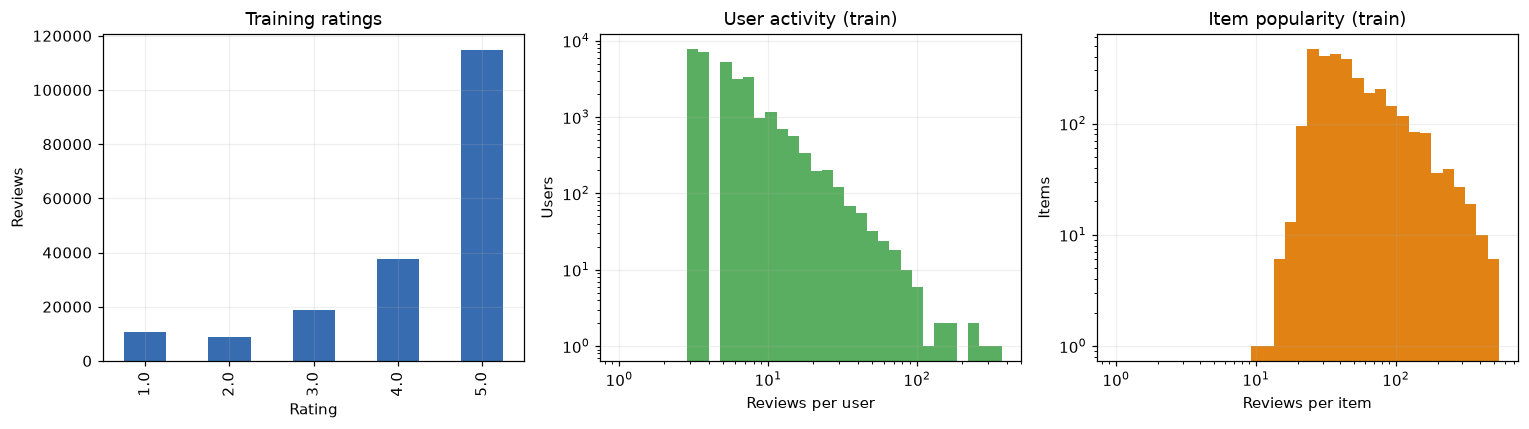

In [3]:
display(pd.Series(diagnostics['missing'], name='missing_required_fields').to_frame())
print('Invalid rows:', diagnostics['invalid_rows'])
print('Repeated user-item pairs removed:', diagnostics['duplicate_pairs_removed'])
print(f"Final sparsity: {diagnostics['sparsity']:.6%}")
activity = dataset.train.groupby('user').size()
popularity = dataset.train.groupby('item').size()
display(pd.DataFrame({'user_activity': activity.describe(), 'item_popularity': popularity.describe()}))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
dataset.train.rating.value_counts().sort_index().plot.bar(ax=axes[0], color='#386cb0')
axes[0].set(title='Training ratings', xlabel='Rating', ylabel='Reviews')
axes[1].hist(activity, bins=np.geomspace(1, activity.max()+1, 35), color='#5aae61')
axes[1].set(xscale='log', yscale='log', title='User activity (train)', xlabel='Reviews per user', ylabel='Users')
axes[2].hist(popularity, bins=np.geomspace(1, popularity.max()+1, 35), color='#e08214')
axes[2].set(xscale='log', yscale='log', title='Item popularity (train)', xlabel='Reviews per item', ylabel='Items')
fig.tight_layout(); fig.savefig('artifacts/eda_activity.png', bbox_inches='tight'); plt.show()

,field,missing
0,title,0
1,brand,11
2,category,16


Metadata rows read: 84819 ; matched items: 2994
Repeated metadata records in selected catalogue: 580


,title,brand
0,Dirt 3,Dirt 3
1,Legend of Zelda Box Set Prima Official Game Guide,DIAMOND SELECT TOYS
2,Silicone Protective Case for Controller (Black),Microsoft
3,Dotop Sony Playstation 2 PS2 64MB Memory Card,Dotop
4,2 Pack - Gator Crunch Wii Gamecube 6FT Extensi...,by\n \n Gator Crunch


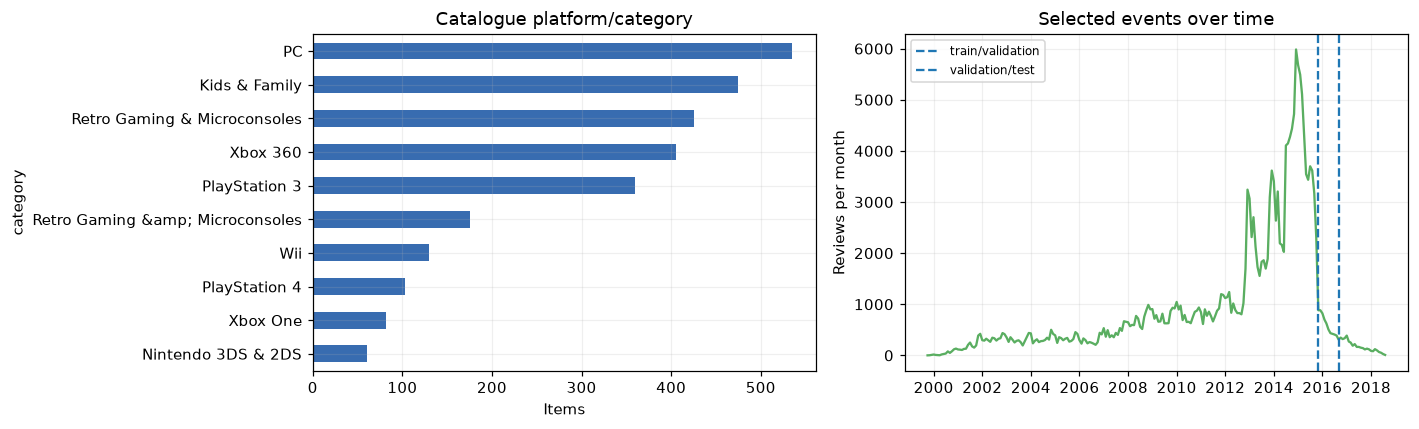

In [4]:
metadata = pd.DataFrame(dataset.metadata)
display(pd.DataFrame({'field': ['title', 'brand', 'category'],
                      'missing': [diagnostics['metadata_missing_title'], diagnostics['metadata_missing_brand'], diagnostics['metadata_missing_category']]}))
print('Metadata rows read:', diagnostics['metadata_raw_rows'], '; matched items:', diagnostics['metadata_items_found'])
print('Repeated metadata records in selected catalogue:', diagnostics['metadata_duplicate_selected_items'])
display(metadata[['title', 'brand']].head(5))
platforms = metadata.category.map(lambda x: x[1] if isinstance(x,list) and len(x)>1 else '<missing>')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
platforms.value_counts().head(10).sort_values().plot.barh(ax=axes[0], color='#386cb0')
axes[0].set(title='Catalogue platform/category', xlabel='Items')
monthly = pd.to_datetime(dataset.selected.timestamp, unit='s', utc=True).dt.strftime('%Y-%m').value_counts().sort_index()
axes[1].plot(pd.to_datetime(monthly.index), monthly.values, color='#5aae61')
for cut,label in [(dataset.train_cutoff,'train/validation'),(dataset.test_cutoff,'validation/test')]:
    axes[1].axvline(pd.to_datetime(cut,unit='s',utc=True),linestyle='--',label=label)
axes[1].set(title='Selected events over time', ylabel='Reviews per month'); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig('artifacts/eda_metadata_time.png', bbox_inches='tight'); plt.show()

## 3. Единый протокол оценки

**Основная метрика до подбора: NDCG@10.** Она учитывает, на каком месте списка показан релевантный
товар. Вторая основная метрика Recall@10 измеряет долю найденных релевантных товаров. Дополнительно
показываем Precision@10 и долю каталога, попавшую в рекомендации (Coverage@10).

Для пользователя $u$ с непустым набором будущих оценок $R_u=\{i:r_{ui}\ge4\}$:

$$\operatorname{Recall@10}(u)=|L_u\cap R_u|/|R_u|,$$
$$\operatorname{NDCG@10}(u)=\frac{\sum_{j=1}^{10}\mathbf1[L_{uj}\in R_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.$$

Усреднение — macro по пользователям с хотя бы одним релевантным событием в соответствующем периоде.
Все модели оцениваются на **одних и тех же** пользователях внутри периода; val и test имеют разные
когорты, поскольку это разные будущие периоды. Пользователи без релевантных событий исключаются из
macro-метрик, их число приводится явно. Кандидаты — **все 3 000** товаров фиксированного train-каталога,
за вычетом любых уже оценённых пользователем товаров, включая оценки 1–3. Сэмплирования кандидатов нет.
Пары не повторяются между периодами. При равенстве score выбирается меньший внутренний ID товара.

На validation модель знает только train. После замораживания настроек каждая модель переобучается
на train+validation и один раз оценивается на test. На test исключаются все известные train+validation
товары. Новые пользователи и товары вне каталога не оцениваются: это **warm-start**, а не cold-start
эксперимент. Таблица покрытия ниже считает исключения по исходной очищенной выборке; две причины
исключения могут пересекаться, поэтому их нельзя складывать.

In [5]:
display(pd.DataFrame([
    {'split': 'train', 'events':len(dataset.train), 'start_UTC':str(pd.to_datetime(dataset.train.timestamp.min(),unit='s',utc=True)), 'end_UTC':str(pd.to_datetime(dataset.train.timestamp.max(),unit='s',utc=True))},
    {'split': 'validation','events':len(dataset.validation),'start_UTC':diagnostics['train_cutoff_utc'],'end_UTC':str(pd.to_datetime(dataset.validation.timestamp.max(),unit='s',utc=True))},
    {'split': 'test','events':len(dataset.test),'start_UTC':diagnostics['test_cutoff_utc'],'end_UTC':str(pd.to_datetime(dataset.test.timestamp.max(),unit='s',utc=True))},
]))
display(pd.DataFrame(diagnostics['phase_coverage']).T)

,split,events,start_UTC,end_UTC
0,train,190864,1999-10-14 00:00:00+00:00,2015-10-20 00:00:00+00:00
1,validation,6498,2015-10-21T00:00:00+00:00,2016-09-06 00:00:00+00:00
2,test,4121,2016-09-07T00:00:00+00:00,2018-08-27 00:00:00+00:00


,original_events,cold_user_events,outside_catalog_events,retained_events
validation,71165,50936,43162,6498
test,71084,54780,48228,4121


## 4. Модели и формулы

### 4.1 ItemKNN: item-based соседство

Пусть $X_{ui}=\mathbf1[r_{ui}\ge4]$ для обучающих событий. Сходство товаров:
$s_{ij}=x_i^Tx_j/(\|x_i\|\|x_j\|+\lambda_s)$, $s_{ii}=0$.
Для каждого целевого товара сохраняются $k$ наиболее похожих соседей;
$\hat y_{uj}=\sum_i X_{ui}s_{ij}$. Shrinkage уменьшает влияние случайных совпадений редких товаров.

### 4.2 Базовый iALS

$O_{ui}=1$ для любой наблюдаемой оценки, $p_{ui}=\mathbf1[r_{ui}\ge4]$,
$c_{ui}=1+\alpha O_{ui}$. Для ненаблюдавшейся пары $p=0,c=1$; для известных низких оценок $p=0,c=1+\alpha$.

$$\min_{U,V}\sum_{ui}c_{ui}(p_{ui}-U_u^TV_i)^2+\lambda(\|U\|_F^2+\|V\|_F^2).$$

Точное обновление пользователя:
$U_u=(V^TV+\alpha\sum_{i:O_{ui}=1}V_iV_i^T+\lambda I)^{-1}
(1+\alpha)\sum_{i:O_{ui}=1}p_{ui}V_i$; обновление товаров симметрично.
Используется `numpy.linalg.solve`, без формирования обратной матрицы в каждом обновлении.

### 4.3 EASE

$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\qquad \operatorname{diag}(B)=0.$$

Для $P=(X^TX+\lambda I)^{-1}$ решение $B_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$,
$B_{ii}=0$; предсказание $XB$. Обращение выполняется через факторизацию Холецкого в SciPy.

### 4.4 FM с метапризнаками

$$\hat y(x)=b+\sum_jw_jx_j+\frac12\sum_f[(\sum_jv_{jf}x_j)^2-\sum_jv_{jf}^2x_j^2].$$

Признаки: ID пользователя и товара; bucket активности пользователя **только по обучающей истории**;
бренд/издатель, платформа из второй категории и первые два слова названия товара. Категориальные
поля кодируются стабильным BLAKE2b-хешем в отдельные пространства: 512, 128, 512 и 512 значений.
Это фиксированное ограничение памяти; возможны коллизии. Отсутствия имеют отдельное исходное значение
`<missing>`; редкие и новые строки обрабатываются тем же хешем без подглядывания в будущие оценки.

Название, издатель и платформа — свойства существующего товара, предполагаемые известными при его
появлении в каталоге. Это явно принятое допущение: исторические версии метаданных датасет не хранит.
Не используются будущие отзывы, их текст, динамические цены, popularity test или user/item mean test.

Оптимизация: собственные градиенты binary cross-entropy и AdaGrad; L2 на активных параметрах batch.
Все известные оценки используются с label $\mathbf1[r\ge4]$, к каждому положительному событию добавляются
три равномерных отрицательных товара, не встречавшихся в **обучающей** истории пользователя. Они не
фильтруются по validation/test. Отрицательные примеры обновляются каждую эпоху при фиксированном seed.
Для ранжирования используется logit; монотонный sigmoid не меняет порядок. Формула FM позволяет
считать полный каталог через скалярные произведения сумм user/item embeddings.

### 4.5 ALS с авторским целевым сигналом

Для наблюдаемого события с возрастом $a_{ui}=(T-t_{ui})/86400$ дней:

$$q_{ui}=\frac{r_{ui}-3}{2}\left[\eta+(1-\eta)2^{-a_{ui}/H}\right],\qquad\eta=0.5.$$

Для отсутствующих событий $q=0$. Оценки 1–2 дают отрицательное предпочтение, 3 — нейтральное,
4–5 — положительное. Свежие наблюдения сильнее отражают текущие интересы; нижняя граница сохраняет
сигнал от старых событий. $T$ — граница рекомендации, обучение содержит только $t<T$.

В **том же** ALS-объективе заменяем **сам таргет $p$ на $q$**. Confidence $c$, факторы,
регуляризация, число итераций и seed совпадают с выбранным базовым iALS. Это изменение правой части
нормальных уравнений, а не только confidence или гиперпараметров. Отрицательный таргет допускается
квадратичной ALS-задачей; это обобщённый signed-preference ALS.
Контроль $\eta=1$ оставляет лишь шкалу оценок и позволяет отдельно проверить эффект давности.
Критерий релевантности на validation/test по-прежнему $r\ge4$.

### Пространство подбора

ItemKNN: соседи {50,100,200}, shrinkage=10. iALS: факторы {32,64}, регуляризация {1,5},
alpha=20, 12 точных ALS-итераций. EASE: регуляризация {50,200,1000}.
FM: (факторы, learning rate) {(16,0.03),(16,0.08),(32,0.05)}, 10 эпох, L2=0.0001,
3 отрицательных примера, batch=2048. Custom ALS: half-life {180,720} дней при eta=0.5,
остальные параметры взяты у лучшего iALS. Выбор по **NDCG@10 validation**, при равенстве —
первая конфигурация в объявленном списке. Пространство небольшое из-за ограниченного бюджета CPU.

Контроль FM с ID использует выбранные параметры FM с метаданными; контроль rating-only ALS
использует выбранные параметры iALS. Это фиксированные ablation-эксперименты, не дополнительный
подбор по test. В `artifacts/selection.json` настройки фиксируются **до** первого вызова test-оценки.

In [6]:
print('Primary metric fixed before training:', PRIMARY_METRIC)
display(pd.DataFrame([{'model': name, 'configurations':len(grid), 'grid':json.dumps(grid)} for name,grid in GRIDS.items()]))
validation_search, frozen_selection = run_validation(dataset)
display(validation_search.drop(columns='config').sort_values(['model','NDCG@10'],ascending=[True,False]))
display(pd.DataFrame([{'model':m,'selected_hyperparameters':json.dumps(c,sort_keys=True)} for m,c in frozen_selection['selected'].items()]))

Primary metric fixed before training: NDCG@10


,model,configurations,grid
0,ItemKNN,3,"[{""neighbors"": 50, ""shrinkage"": 10.0}, {""neigh..."
1,iALS,4,"[{""factors"": 32, ""regularization"": 1.0, ""alpha..."
2,EASE,3,"[{""regularization"": 50.0}, {""regularization"": ..."
3,FM+metadata,3,"[{""factors"": 16, ""learning_rate"": 0.03, ""epoch..."


Validation: ItemKNN 1/3 {'neighbors': 50, 'shrinkage': 10.0}


  NDCG@10=0.042538, Recall@10=0.075173, fit=0.5s


Validation: ItemKNN 2/3 {'neighbors': 100, 'shrinkage': 10.0}


...

  NDCG@10=0.010429, Recall@10=0.018670, fit=25.4s


Validation: Custom ALS (rating only) 1/1 {'factors': 64, 'regularization': 1.0, 'alpha': 20.0, 'iterations': 12, 'seed': 42, 'half_life_days': 1000000000000.0, 'freshness_floor': 1.0}


  NDCG@10=0.035515, Recall@10=0.063138, fit=25.9s


,model,config_id,Recall@10,NDCG@10,Precision@10,users,Coverage@10,fit_seconds,evaluation_seconds
13,Custom ALS,0,0.073645,0.041851,0.013208,2862,0.440667,26.689239,0.759057
14,Custom ALS,1,0.068478,0.039476,0.012579,2862,0.436333,26.062334,0.762239
16,Custom ALS (rating only),0,0.063138,0.035515,0.011740,2862,0.438667,25.879838,0.765733
7,EASE,0,0.081474,0.046110,0.014430,2862,0.735000,1.715766,3.129759
8,EASE,1,0.080265,0.044255,0.014081,2862,0.654333,1.800537,3.074960
9,EASE,2,0.072369,0.040090,0.012893,2862,0.586333,1.819472,3.083679
15,FM (IDs only),0,0.018670,0.010429,0.003249,2862,0.005333,25.398707,0.807406
12,FM+metadata,2,0.040020,0.020758,0.007442,2862,0.168000,62.899708,0.795950
10,FM+metadata,0,0.035710,0.020386,0.006604,2862,0.089667,40.795551,0.894942
11,FM+metadata,1,0.036937,0.019927,0.006848,2862,0.153333,39.510274,0.963817


,model,selected_hyperparameters
0,ItemKNN,"{""neighbors"": 50, ""shrinkage"": 10.0}"
1,iALS,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 1..."
2,EASE,"{""regularization"": 50.0}"
3,FM+metadata,"{""batch_size"": 2048, ""epochs"": 10, ""factors"": ..."
4,Custom ALS,"{""alpha"": 20.0, ""factors"": 64, ""freshness_floo..."
5,FM (IDs only),"{""batch_size"": 2048, ""epochs"": 10, ""factors"": ..."
6,Custom ALS (rating only),"{""alpha"": 20.0, ""factors"": 64, ""freshness_floo..."


### Зафиксированные параметры полученного запуска

| Модель | Параметры, выбранные до оценки test |
|---|---|
| ItemKNN | neighbors=50, shrinkage=10 |
| iALS | factors=64, regularization=1, alpha=20, iterations=12 |
| EASE | regularization=50 |
| FM с метаданными | factors=32, learning_rate=0.05, epochs=10, regularization=0.0001, negatives=3, batch_size=2048 |
| Custom ALS | все параметры выбранного iALS; half_life_days=180, freshness_floor=0.5 |
| FM с ID, контроль | те же параметры обучения, что у FM с метаданными |
| ALS rating-only, контроль | все параметры выбранного iALS; freshness_floor=1, временное затухание выключено |

Для всех стохастических моделей seed=42. Это документирование опубликованного запуска;
программный источник выбранных значений — `artifacts/selection.json`, записанный до test.

## 5. Финальное сравнение на test

Теперь настройки зафиксированы. Каждая модель обучается заново на train+validation;
после этой ячейки ни настройки, ни признаки не меняются по результатам test.
NDCG-интервалы и разности вычисляются непараметрическим bootstrap по пользователям,
1 000 повторений, seed=42. В парном сравнении индекс пользователя одинаков для двух моделей.
Это интервалы условно на выбранной выборке и разбиении, они не учитывают неопределённость
выбора датасета, модели или будущего временного периода.

In [7]:
test_results, report, recommendation_examples = run_test(dataset, frozen_selection)
main_models = ['ItemKNN','iALS','EASE','FM+metadata','Custom ALS']
display(test_results[test_results.model.isin(main_models)].reset_index(drop=True))
display(test_results[~test_results.model.isin(main_models)].reset_index(drop=True))
print('Number of identical test users for every model:', report['test_users'])
print('Test retained users without positive labels:', dataset.test.user.nunique() - report['test_users'])
display(pd.DataFrame(report['paired_comparisons']).T)

Final train+validation fit: ItemKNN


  test NDCG@10=0.030987, Recall@10=0.056172


Final train+validation fit: iALS


  test NDCG@10=0.037186, Recall@10=0.065396


Final train+validation fit: EASE


...

  test NDCG@10=0.029508, Recall@10=0.052218


,model,Recall@10,NDCG@10,Precision@10,users,Coverage@10,NDCG_CI_low,NDCG_CI_high,fit_seconds,evaluation_seconds,config
0,iALS,0.065396,0.037186,0.011292,1904,0.443000,0.031336,0.043763,26.362293,0.517916,"{'factors': 64, 'regularization': 1.0, 'alpha'..."
1,EASE,0.064185,0.036455,0.010557,1904,0.683667,0.030968,0.042766,1.517399,1.765264,{'regularization': 50.0}
2,Custom ALS,0.055840,0.031426,0.009454,1904,0.418000,0.026106,0.036687,26.446801,0.521057,"{'factors': 64, 'regularization': 1.0, 'alpha'..."
3,ItemKNN,0.056172,0.030987,0.009611,1904,0.831667,0.025510,0.036373,0.483751,0.309571,"{'neighbors': 50, 'shrinkage': 10.0}"
4,FM+metadata,0.052562,0.028132,0.007563,1904,0.154000,0.022942,0.033644,65.753131,0.534287,"{'factors': 32, 'learning_rate': 0.05, 'epochs..."


,model,Recall@10,NDCG@10,Precision@10,users,Coverage@10,NDCG_CI_low,NDCG_CI_high,fit_seconds,evaluation_seconds,config
0,Custom ALS (rating only),0.052218,0.029508,0.008981,1904,0.420,0.023983,0.035078,26.752480,0.518162,"{'factors': 64, 'regularization': 1.0, 'alpha'..."
1,FM (IDs only),0.031282,0.013167,0.004674,1904,0.005,0.010290,0.016161,32.865869,0.536185,"{'factors': 32, 'learning_rate': 0.05, 'epochs..."


Number of identical test users for every model: 1904
Test retained users without positive labels: 461


,mean_ndcg_difference,paired_bootstrap_95pct
Custom ALS minus iALS,-0.00576,"[-0.01076, -0.000859]"
FM+metadata minus FM (IDs only),0.014965,"[0.010016, 0.020516]"
Custom ALS minus Custom ALS (rating only),0.001918,"[-0.000416, 0.004217]"


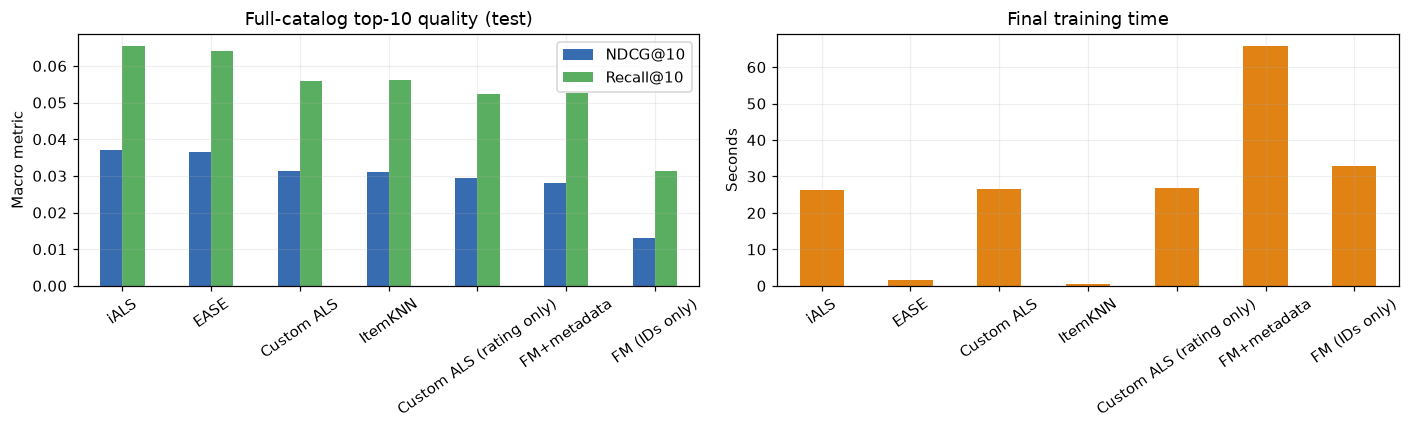

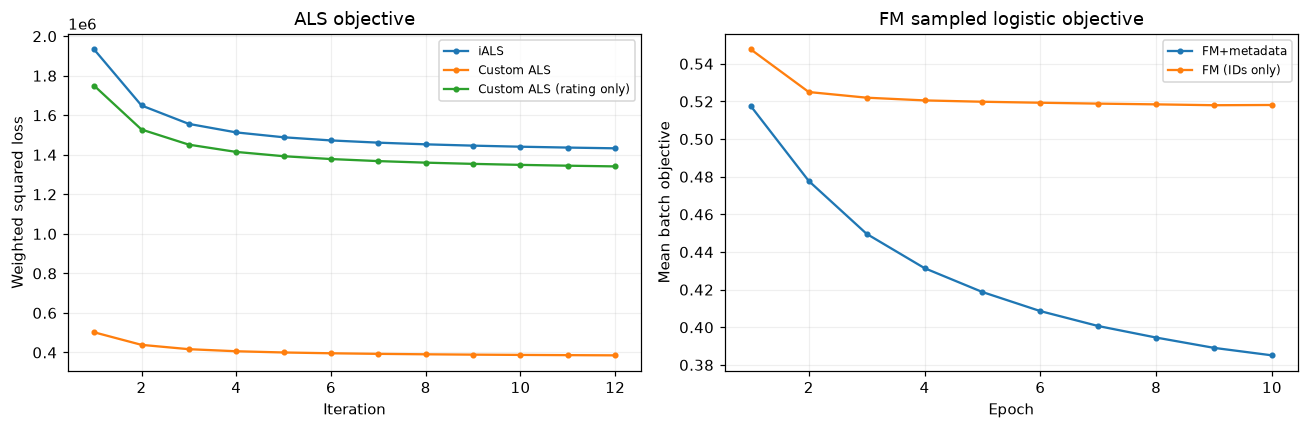

In [8]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
plot_table = test_results.set_index('model')
plot_table[['NDCG@10','Recall@10']].plot.bar(ax=axes[0], color=['#386cb0','#5aae61'])
axes[0].set(title='Full-catalog top-10 quality (test)', xlabel='', ylabel='Macro metric')
axes[0].tick_params(axis='x',rotation=35)
plot_table['fit_seconds'].plot.bar(ax=axes[1], color='#e08214')
axes[1].set(title='Final training time',xlabel='',ylabel='Seconds'); axes[1].tick_params(axis='x',rotation=35)
fig.tight_layout(); fig.savefig('artifacts/test_comparison.png',bbox_inches='tight'); plt.show()
fig, axes = plt.subplots(1,2,figsize=(12,4))
for name,curve in report['final_loss_curves'].items():
    if not curve: continue
    axis = axes[1] if name.startswith('FM') else axes[0]
    axis.plot(np.arange(1,len(curve)+1),curve,label=name,marker='.')
axes[0].set(title='ALS objective',xlabel='Iteration',ylabel='Weighted squared loss')
axes[1].set(title='FM sampled logistic objective',xlabel='Epoch',ylabel='Mean batch objective')
for axis in axes: axis.legend(fontsize=8)
fig.tight_layout(); fig.savefig('artifacts/training_curves.png',bbox_inches='tight'); plt.show()

### Пример персонального списка

Покажем рекомендации для первого по внутреннему ID пользователя из фиксированной test-когорты.
Это иллюстрация, а не дополнительная оценка. В исходном каталоге могут быть разные издания одной
игры: разные ASIN считаются разными товарами, поэтому семантические повторы названий возможны.

In [9]:
best_name = test_results[test_results.model.isin(main_models)].iloc[0].model
display(recommendation_examples[recommendation_examples.model == best_name])

,model,anonymous_user,rank,title,brand
10,iALS,1,1,Sports Champions 2 - Playstation 3,by\n \n Sony
11,iALS,1,2,PlayStation Eye,by\n \n Sony
12,iALS,1,3,The Fight,by\n \n Sony
13,iALS,1,4,PS3 Move Quad Charger,by\n \n dreamGEAR
14,iALS,1,5,Sony PlayStation 3 Move Motion Controller (Bul...,by\n \n Sony
15,iALS,1,6,PS3 Everybody Dance,by\n \n Sony
16,iALS,1,7,Medieval Moves: Deadmund's Quest - Playstation 3,by\n \n Sony
17,iALS,1,8,Deadmund's Quest Move Bundle - Playstation 3,by\n \n Sony
18,iALS,1,9,PS3 Gran Turismo 5 XL Edition,by\n \n Sony
19,iALS,1,10,PS3 Little Big Planet 2 Special Edition,by\n \n Sony


## 6. Выводы по полученным результатам

In [10]:
main = test_results[test_results.model.isin(main_models)].sort_values('NDCG@10',ascending=False)
best, worst = main.iloc[0], main.iloc[-1]
lines = [f"**Лучший результат среди пяти основных моделей:** {best.model}: NDCG@10={best['NDCG@10']:.5f}, Recall@10={best['Recall@10']:.5f}.",
         f"Наименьший NDCG@10 у {worst.model}: {worst['NDCG@10']:.5f}. Выбранные параметры приведены в таблице выше и в `selection.json`."]
for comparison,result in report['paired_comparisons'].items():
    low,high = result['paired_bootstrap_95pct']
    direction = 'увеличение' if result['mean_ndcg_difference']>0 else 'снижение'
    uncertainty = 'Интервал включает ноль: убедительного различия на этой когорте не видно.' if low<=0<=high else 'Интервал не включает ноль на этой фиксированной когорте.'
    lines.append(f"**{comparison}**: {direction} NDCG@10 на {result['mean_ndcg_difference']:+.5f}; парный 95% bootstrap [{low:+.5f}, {high:+.5f}]. {uncertainty}")
fm_delta = report['paired_comparisons']['FM+metadata minus FM (IDs only)']['mean_ndcg_difference']
lines.append('Метаданные улучшили FM при одинаковых настройках.' if fm_delta>0 else 'В данном ограниченном подборе метаданные не улучшили FM; статические признаки и коллизии хеширования могут не отражать индивидуальный вкус.')
custom_delta = report['paired_comparisons']['Custom ALS minus iALS']['mean_ndcg_difference']
lines.append('Авторский таргет оказался полезен по сравнению с базовым бинарным таргетом.' if custom_delta>0 else 'Авторский таргет не улучшил базовый iALS: знак оценки и затухание могут ослаблять полезные старые предпочтения, тогда как тестовая релевантность бинарна.')
display(Markdown('\n\n'.join(lines)))
Path('artifacts/conclusions.md').write_text('\n\n'.join(lines),encoding='utf-8')

**Лучший результат среди пяти основных моделей:** iALS: NDCG@10=0.03719, Recall@10=0.06540.

Наименьший NDCG@10 у FM+metadata: 0.02813. Выбранные параметры приведены в таблице выше и в `selection.json`.

**Custom ALS minus iALS**: снижение NDCG@10 на -0.00576; парный 95% bootstrap [-0.01076, -0.00086]. Интервал не включает ноль на этой фиксированной когорте.

**FM+metadata minus FM (IDs only)**: увеличение NDCG@10 на +0.01497; парный 95% bootstrap [+0.01002, +0.02052]. Интервал не включает ноль на этой фиксированной когорте.

**Custom ALS minus Custom ALS (rating only)**: увеличение NDCG@10 на +0.00192; парный 95% bootstrap [-0.00042, +0.00422]. Интервал включает ноль: убедительного различия на этой когорте не видно.

Метаданные улучшили FM при одинаковых настройках.

Авторский таргет не улучшил базовый iALS: знак оценки и затухание могут ослаблять полезные старые предпочтения, тогда как тестовая релевантность бинарна.

932

### Качество, скорость и ширина рекомендаций

На validation максимальный NDCG@10 был у EASE с regularization=50 (0.04611), а на test
наибольшее наблюдаемое значение получил iALS с 64 факторами и regularization=1 (0.03719).
У EASE на test 0.03645. Это не основание переоптимизировать параметры по test;
разница между этими двумя моделями мала, и отдельное утверждение о статистическом
превосходстве iALS над EASE здесь не делается.

EASE обучается заметно быстрее iALS на выбранном небольшом каталоге (времена приведены в таблице выше).
Если важна скорость обучения на данном небольшом каталоге, EASE выглядит практичным выбором.
ItemKNN дал самое широкое покрытие каталога среди основных моделей: 83.17%, EASE — 68.37%,
iALS — 44.30%. Более высокое покрытие само по себе не означает более высокую точность.
Времена относятся к данному CPU и не являются универсальным benchmark.

У FM метаданные подняли NDCG@10 с 0.01317 до 0.02813, однако FM всё ещё уступает
остальным основным моделям при выделенном бюджете подбора. Авторский таргет ALS дал
0.03143 против 0.03719 базового iALS. По сравнению с rating-only контролем затухание
дало +0.00192 NDCG, но парный интервал включает ноль, поэтому отдельную пользу давности
на этой когорте уверенно подтвердить нельзя.

### Ограничения и интерпретация

- Это warm-start сравнение на исторически популярных 3 000 товарах, а не оценка всего магазина.
  Таблица покрытия показывает большую долю исключённых событий. Результаты нельзя переносить на
  новых пользователей и новые релизы; реальный сервис потребовал бы отдельного cold-start решения.
- Исходный 5-core построен авторами по полной истории, что уже создаёт смещение к активным участникам.
  Пользовательский отбор дополнительно требует три train-события. Временное глобальное разбиение
  предотвращает обучение на будущих взаимодействиях, но не устраняет эти смещения исходной выборки.
- Оценка является меткой интереса с задержкой, а неизвестный товар — непроверенным отрицательным
  примером. Нет показов, propensity scores и реального онлайн CTR; offline-метрики не равны онлайн-эффекту.
- Каталог содержит аксессуары и разные издания. Дубли пар удалены, однако семантически одинаковые
  товары с разными ASIN не объединялись. Часть метаданных отсутствует, временные версии не доступны.
- FM-подбор ограничен тремя конфигурациями, обе ablation-модели не получают отдельного расширенного
  бюджета. Поэтому влияние метаданных оценивается при **фиксированных** настройках, а не как предел
  качества всех возможных content-aware моделей.
- Один seed и одно временное разбиение ограничивают устойчивость выводов. Bootstrap оценивает
  неопределённость между пользователями, но не между периодами и повторными обучениями.
- EASE требует $O(I^2)$ памяти и $O(I^3)$ вычислений; ItemKNN строит плотную item-item матрицу.
  Выбранный размер каталога делает обе реализации доступными на обычном CPU.